# The Curse of Dimensionality: see it, detect it, fix it

Richard **Bellman** introduced the term in 1957, while studying dynamic programming.
He noticed that the work required grows **exponentially** with the number of variables.

This notebook shows three things:
1. **Why it happens**: space becomes empty and distances stop being informative.
2. **How to detect it** in your own project.
3. **How to fix it**, measured on real data.

**The dataset.** *Banknote Authentication* (UCI): 1,372 samples with 4 informative features. We deliberately add useless features.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Why it happens: distances lose their meaning

Take random points in a cube and measure the **relative contrast**:

$$\text{contrast} = \frac{d_{\max} - d_{\min}}{d_{\min}}$$

If it approaches zero, the nearest and the farthest points are almost equally far away, so "nearest neighbor" means little.

In [3]:
rng = np.random.default_rng(SEED)
dimensions = [1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000]
contrast = []
for d in dimensions:
    points = rng.random((1000, d))
    query = rng.random((200, d))
    # Distance from every query point to all 1000 points.
    distances = np.sqrt(((query[:, None, :] - points[None, :, :]) ** 2).sum(axis=2))
    contrast.append(float(np.mean((distances.max(axis=1) - distances.min(axis=1)) / distances.min(axis=1))))
    print(f"d = {d:5d}  contrast = {contrast[-1]:10.3f}")

d =     1  contrast =  10583.469
d =     2  contrast =     92.282
d =     3  contrast =     25.273
d =     5  contrast =      7.426
d =    10  contrast =      2.866
d =    20  contrast =      1.434


d =    50  contrast =      0.699


d =   100  contrast =      0.438


d =   200  contrast =      0.285


d =   500  contrast =      0.172


d =  1000  contrast =      0.119


## 2. Why it happens: space becomes empty

To cover 10% of the volume of a unit cube, a smaller cube needs an edge of $0.1^{1/d}$.
In 100 dimensions that edge is about 0.98: a "local" neighborhood spans almost the entire range of every feature.

Also, keeping 10 grid points per axis needs $10^d$ samples.

In [4]:
edge_dims = np.arange(1, 101)
edge_length = 0.1 ** (1 / edge_dims)
print(f"Edge needed in  d=1: {edge_length[0]:.2f}")
print(f"Edge needed in d=10: {edge_length[9]:.2f}")
print(f"Edge needed in d=100: {edge_length[99]:.2f}")

Edge needed in  d=1: 0.10
Edge needed in d=10: 0.79
Edge needed in d=100: 0.98


## 3. Get real data, then add useless features

In [5]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "banknote"
archive = download("https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\banknote\dataset.zip
Files: ['dataset.zip', 'data_banknote_authentication.txt']


In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(DATA_DIR / "data_banknote_authentication.txt", header=None)
X_real, y = df.iloc[:, :4].to_numpy(), df.iloc[:, 4].to_numpy()

def with_noise(X, count):
    """Append `count` columns of pure random noise (same scale as standardized features)."""
    X = StandardScaler().fit_transform(X)
    noise = np.random.default_rng(SEED).normal(size=(len(X), count))
    return np.hstack([X, noise])

noise_levels = [0, 2, 5, 10, 20, 50, 100, 200, 500]
train_acc, test_acc = [], []
for count in noise_levels:
    X_train, X_test, y_train, y_test = train_test_split(with_noise(X_real, count), y, test_size=0.3, stratify=y, random_state=SEED)
    knn = KNeighborsClassifier(5).fit(X_train, y_train)
    train_acc.append(knn.score(X_train, y_train))
    test_acc.append(knn.score(X_test, y_test))
    print(f"noise features = {count:4d}  train = {train_acc[-1]:.3f}  test = {test_acc[-1]:.3f}")

noise features =    0  train = 0.998  test = 1.000
noise features =    2  train = 0.986  test = 0.976


noise features =    5  train = 0.968  test = 0.956


noise features =   10  train = 0.944  test = 0.891


noise features =   20  train = 0.885  test = 0.818
noise features =   50  train = 0.847  test = 0.716
noise features =  100  train = 0.787  test = 0.665
noise features =  200  train = 0.747  test = 0.553


noise features =  500  train = 0.717  test = 0.573


## 4. How to detect the problem

Warning signs, all measured below:

| Sign | What to check |
|---|---|
| **Few samples per feature** | The ratio samples / features is small |
| **Accuracy drops as features are added** | Plot performance against the number of features |
| **Distance-based models fail while others do not** | Compare KNN with a tree-based model |
| **Low intrinsic dimension** | PCA needs far fewer components than there are features |
| **Weak distance contrast** | Relative contrast of real distances is close to zero |

In [7]:
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import pairwise_distances

NOISE = 200
X_high = with_noise(X_real, NOISE)
X_train, X_test, y_train, y_test = train_test_split(X_high, y, test_size=0.3, stratify=y, random_state=SEED)

def data_contrast(X):
    d = pairwise_distances(X[:300])
    d[d == 0] = np.nan   # ignores each point itself, and exact duplicate rows in the dataset
    # The median is used because a few almost-identical samples would otherwise dominate the average.
    return float(np.nanmedian((np.nanmax(d, axis=1) - np.nanmin(d, axis=1)) / np.nanmin(d, axis=1)))

samples_per_feature = len(X_train) / X_train.shape[1]
contrast_low, contrast_high = data_contrast(with_noise(X_real, 0)), data_contrast(X_high)
knn_high = KNeighborsClassifier(5).fit(X_train, y_train).score(X_test, y_test)
forest_high = RandomForestClassifier(300, n_jobs=-1, random_state=SEED).fit(X_train, y_train).score(X_test, y_test)

print(f"Samples per feature: {samples_per_feature:.1f}")
print(f"Relative contrast: {contrast_low:.2f} with 4 features, {contrast_high:.2f} with {X_high.shape[1]} features")
print(f"KNN accuracy: {knn_high:.3f} | Random forest accuracy: {forest_high:.3f}")

Samples per feature: 4.7
Relative contrast: 25.14 with 4 features, 0.28 with 204 features
KNN accuracy: 0.553 | Random forest accuracy: 0.915


## 5. How to fix it

- **Feature selection** keeps only the columns related to the target.
- **Feature extraction** (PCA, autoencoders) builds a few new features.
- **Regularization** (L1) pushes useless weights to zero.
- **More data** helps, but the amount needed grows very quickly.
- **Domain knowledge** removes columns before modeling even starts.

Every method below is fitted only on training data, through a pipeline.

In [8]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

methods = {
    f"KNN, {X_high.shape[1]} features": make_pipeline(KNeighborsClassifier(5)),
    "PCA (10) + KNN": make_pipeline(PCA(n_components=10, random_state=SEED), KNeighborsClassifier(5)),
    "SelectKBest (10) + KNN": make_pipeline(SelectKBest(f_classif, k=10), KNeighborsClassifier(5)),
    "L1 Logistic": make_pipeline(LogisticRegression(penalty="l1", solver="liblinear", C=0.1)),
}
fix_scores = {name: pipe.fit(X_train, y_train).score(X_test, y_test) for name, pipe in methods.items()}

X_clean_train, X_clean_test, y_tr, y_te = train_test_split(with_noise(X_real, 0), y, test_size=0.3, stratify=y, random_state=SEED)
fix_scores["KNN, original 4 features"] = KNeighborsClassifier(5).fit(X_clean_train, y_tr).score(X_clean_test, y_te)

for name, score in fix_scores.items():
    print(f"{name:32s} {score:.3f}")

KNN, 204 features                0.553
PCA (10) + KNN                   0.636
SelectKBest (10) + KNN           0.905
L1 Logistic                      0.971
KNN, original 4 features         1.000


## 6. Summary figure

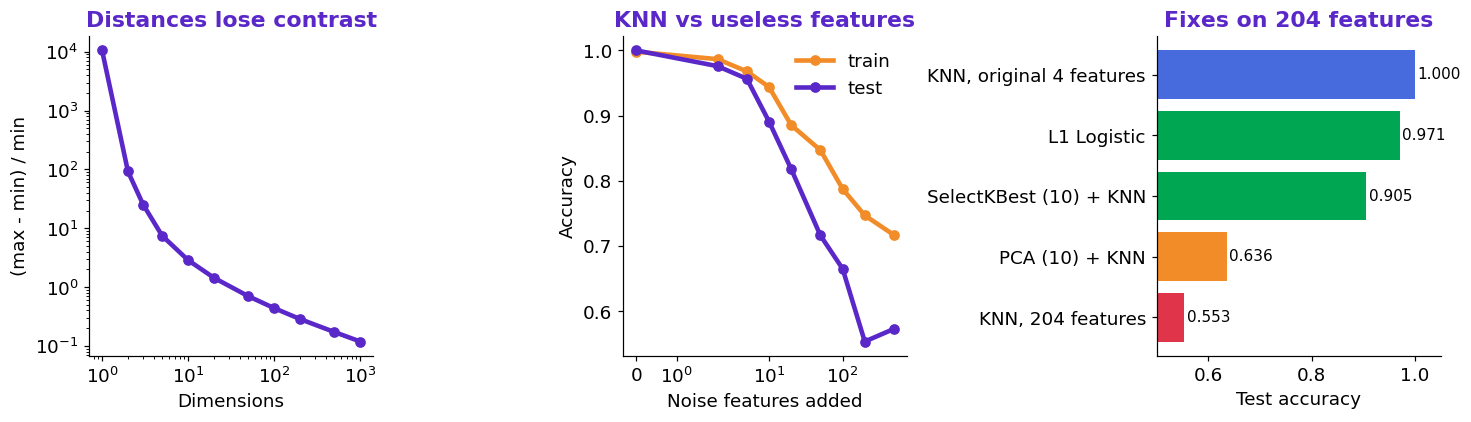

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4))

ax[0].loglog(dimensions, contrast, color=PURPLE, lw=3, marker="o")
ax[0].set(title="Distances lose contrast", xlabel="Dimensions", ylabel="(max - min) / min")

ax[1].plot(noise_levels, train_acc, color=ORANGE, lw=3, marker="o", label="train")
ax[1].plot(noise_levels, test_acc, color=PURPLE, lw=3, marker="o", label="test")
ax[1].set_xscale("symlog", linthresh=2)
ax[1].set(title="KNN vs useless features", xlabel="Noise features added", ylabel="Accuracy")
ax[1].legend()

names = list(fix_scores)
values = [fix_scores[n] for n in names]
bars = ax[2].barh(names, values, color=[RED, ORANGE, GREEN, GREEN, BLUE])
ax[2].set(title="Fixes on 204 features", xlabel="Test accuracy", xlim=(0.5, 1.05))
for bar, value in zip(bars, values):
    ax[2].text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", fontsize=10)
fig.tight_layout()
plt.show()

In [10]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "09_curse_of_dimensionality.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Curse of Dimensionality",
    "dataset": "Banknote Authentication (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"KNN (4 features)": round(float(fix_scores["KNN, original 4 features"]), 3), "KNN (204 features)": round(float(knn_high), 3), "PCA + KNN": round(float(fix_scores["PCA (10) + KNN"]), 3), "SelectKBest + KNN": round(float(fix_scores["SelectKBest (10) + KNN"]), 3), "L1 Logistic": round(float(fix_scores["L1 Logistic"]), 3), "Contrast 4D": round(contrast_low, 2), "Contrast 204D": round(contrast_high, 2), "Samples per feature": round(samples_per_feature, 1), "Random forest (204)": round(float(forest_high), 3), "Edge d=10": round(float(edge_length[9]), 2), "Edge d=100": round(float(edge_length[99]), 2)},
}
(results_dir / "09_curse_of_dimensionality.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Curse of Dimensionality",
  "dataset": "Banknote Authentication (UCI)",
  "n_samples": 1372,
  "metrics": {
    "KNN (4 features)": 1.0,
    "KNN (204 features)": 0.553,
    "PCA + KNN": 0.636,
    "SelectKBest + KNN": 0.905,
    "L1 Logistic": 0.971,
    "Contrast 4D": 25.14,
    "Contrast 204D": 0.28,
    "Samples per feature": 4.7,
    "Random forest (204)": 0.915,
    "Edge d=10": 0.79,
    "Edge d=100": 0.98
  }
}


## What to remember
- More features are not automatically better. Useless ones actively damage distance-based models.
- PCA maximizes variance and ignores the target. When noise is strong, supervised selection can work better.
- The same curse explains the rule explosion in fuzzy systems: with M membership functions and n inputs, there are M to the power n rules.